# Lab 1, Core B: The DFT as a change of basis
### <div align="right"> Linear Algebra for Data Science, MSc DS &mdash; UCU APPS </div>

## Completed by:
*   Oleksandr Korniienko
*   Liubomyr Smerek


### What this core is about

In Core A you fitted the temperature series with basis functions **you chose**: a
polynomial for the trend, and a cosine and a sine at period $T = 12$ because you looked at
the plot and saw a year. The fit was good because the guess was good.

Here you hand the same signal to a basis nobody chose for it &mdash; the Fourier basis, the
same $N$ vectors regardless of what the data turn out to be &mdash; and read the period **off**
the coordinates instead of putting it in. Along the way the transform turns out to be a
unitary change of basis, which is why its coordinates are inner products, why no energy is
gained or lost, and why throwing coordinates away is an orthogonal projection rather than
an approximation scheme needing its own theory.

Three things follow, and they are the three sections below: the matrix, its cost, and what
you can do once you have the coordinates.

### Marking

**Core B** of Lab 1, worth 2 of the lab's 6 points, awarded at the **oral defence**.
Individual cells carry no separate marks.

**Bonus.** The three extensions are the only route to the bonus point. They are marked
$\star$ and sit at the **end** of the notebook they build on: Extensions 1 and 2 at the end
of Core A, Extension 3 at the end of this one. Attempt at most one; a second earns nothing.

### Ground rules

* Build the transform yourself. `np.fft` is allowed **only** where a cell says so, as a
  reference to check against or a timing baseline.
* Complex arithmetic throughout. Recall the convention from the notes: the inner product
  on $\mathbb{C}^N$ is $\langle \mathbf{x}, \mathbf{y}\rangle = \mathbf{x}^{*}\mathbf{y}$,
  conjugating the **first** argument, and $U$ is unitary when $U^{*}U = I$.
* In `numpy`, `A.conj().T` is the adjoint. `A.T` alone is a common and silent bug here.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
from time import perf_counter


In [2]:
temp_data = pd.read_csv("land-temp-1850-2015.csv")
temp_data["date"] = pd.to_datetime(temp_data["date"])

y = temp_data["avg_temp"].to_numpy()
N = y.shape[0]
print(f"N = {N} monthly readings, {temp_data['date'].min():%Y-%m} to {temp_data['date'].max():%Y-%m}")

# Same series as Core A: Berkeley Earth global land average, 1850-2015.
# See Core A section 0 for what it is and why it starts in 1850.


N = 1992 monthly readings, 1850-01 to 2015-12


# SELFNOTE
**It's nice to read this before diving in**


Fourier analysis is a way to describe a signal as a combination of simple waves.

Suppose a signal contains $N$ measurements:

$$
x = (x_0, x_1, \ldots, x_{N-1}).
$$

Instead of describing $x$ by its values at individual times, the Fourier transform describes it by asking how much of each frequency is present:

- a constant wave;
- a wave completing one cycle;
- a wave completing two cycles;
- and so on.

Each wave is a vector called a **Fourier basis vector**. These vectors form the columns of the Fourier matrix $F$.

The Fourier basis vectors are **orthonormal**:

- **Orthogonal:** different frequencies have inner product zero, so they do not overlap mathematically.
- **Normalised:** every basis vector has length one.

Therefore, every signal can be written uniquely as

$$
x = c_0f_0 + c_1f_1 + \cdots + c_{N-1}f_{N-1},
$$

where $c_k$ tells us how much of frequency $k$ is present in the signal.

Because the basis is orthonormal, each coefficient is easy to calculate:

$$
c_k = \langle f_k, x \rangle.
$$

Thus, Fourier analysis describes data using frequencies, while orthonormality makes those frequency components independent, numerically stable, and easy to compute.

---
## 1. The Fourier matrix, and what makes it a basis

Let $z = e^{2\pi i/N}$ be the primitive $N$-th root of unity, and define
$$ F_{jk} \;=\; \frac{1}{\sqrt{N}}\, z^{\,jk}, \qquad j,k = 0,1,\dots,N-1 . $$
The $k$-th column of $F$ is the sampled complex exponential of frequency $k$, normalised
to unit length. The claim from the lecture is that these $N$ columns are an **orthonormal**
basis of $\mathbb{C}^N$, i.e. that $F$ is unitary. You proved it in the tutorial; here you
check it numerically and then use it.


In [3]:
def fourier_matrix(n: int) -> np.ndarray:
    """The n x n unitary Fourier matrix F with F[j,k] = z**(j*k)/sqrt(n).

    Build it with numpy broadcasting, not a double Python loop.
    Hint: np.outer(np.arange(n), np.arange(n)) gives the matrix of exponents.
    """
    # ========= YOUR CODE STARTS HERE ========= #
    # SELFNOTE: define complex number (2j is imaginary unit 2i) using formula given above
    z = np.exp(2j * np.pi / n)

    # SELFNOTE:
    # arange: create vector [0, stop)
    # outer: outer product (we transpose the second argument)
    # TODO: demystify broadcasting
    # in result we get matrix with _jk_ values
    exponents = np.outer(np.arange(n), np.arange(n))
    F = z**exponents / np.sqrt(n)
    # ========== YOUR CODE ENDS HERE ========== #
    return F


def test_fourier_matrix():
    F = fourier_matrix(4)
    assert F.shape == (4, 4) and np.iscomplexobj(F)
    assert np.allclose(F[:, 0], 0.5), "column 0 should be constant 1/sqrt(4)"
    assert np.allclose(F.conj().T @ F, np.eye(4), atol=1e-12), "F is not unitary"
    print("TEST 1: SUCCESS")

test_fourier_matrix()


TEST 1: SUCCESS


### **1.1** Unitary, and what it buys

For $N = 8$, compute and report:

1. $\|F^{*}F - I\|$. State what magnitude counts as zero here and why it is not exactly zero.
2. $\operatorname{cond}(F)$. Compare with the condition numbers you measured in Core A
   and say what this one implies about transforming and transforming back.
3. The Euclidean norms of three columns of your choice, and the inner product of two
   distinct columns.

Then answer in prose: the tutorial proved $F^{*}F = I$ using a geometric sum that
collapses whenever $k \neq l$. Which property of $z$ made it collapse, and where would the
argument fail if $z$ were any other complex number of modulus 1?


In [4]:
# ========= YOUR CODE STARTS HERE ========= #
F8 = fourier_matrix(8)

# SELFNOTE: unitary matrix is just orthogonal matrix but values of which are complex numbers
# Therefore for real matrix we have Q^TQ=I and for complex matrix we have
# U^*U=I (U^* being conjugate transpose)
# I don't exactly why but:
# "The conjugation is necessary for complex inner products and lengths to work correctly."
# The properties for unitary matrix remain the same as for orthogonal matrix
# SELFNOTE: A unitarity error in linear algebra or numerical
# computing measures how much a computed matrix U deviates from being a unitary matrix
unitarity_error = np.linalg.norm(F8.conj().T @ F8 - np.eye(8))
condition_number = np.linalg.cond(F8)
chosen_columns = (0, 1, 2)
column_norms = [np.linalg.norm(F8[:, k]) for k in chosen_columns]
inner_product = np.vdot(F8[:, 3], F8[:, 5])

print(f"||F*F - I|| = {unitarity_error:.3e}")
print(f"cond(F) = {condition_number:.16f}")
for k, norm in zip(chosen_columns, column_norms):
    print(f"||f{k}|| = {norm:.16f}")
print(f"<f3, f5> = {inner_product}")
# ========== YOUR CODE ENDS HERE ========== #


||F*F - I|| = 1.810e-15
cond(F) = 1.0000000000000004
||f0|| = 0.9999999999999999
||f1|| = 0.9999999999999999
||f2|| = 0.9999999999999999
<f3, f5> = (-1.6653345369377348e-16+1.0408340855860764e-16j)


---
1. The value $\|F^{*}F-I\| \approx 1.81\times10^{-15}$ is zero because it's on the edge of double-precision accuracy (~15-17 significant digits). It's not exactly zero because of nature of values ($e^{2\pi i/8}$) being used to fill _F_. When we calculate them and then multiply them we cannot avoid some roundings causing errors to accumulate.

2. TODO: compare cond(F) to core A. From ChatGPT: 
> $\operatorname{cond}(F) \approx 1.0000000000000004$, i.e. 1 up to rounding. This is the smallest possible condition number and is much better than the larger condition numbers from Core A: applying the transform and then its inverse does not amplify relative errors (apart from ordinary floating-point rounding).

3. For columns 0, 1, and 2, the computed Euclidean norms are all $0.9999999999999999 \approx 1$. For two distinct columns, $\langle f3,f5\rangle \approx -1.67\times10^{-17}+1.04\times10^{-16}i \approx 0$. Thus the numerical results agree with the columns being orthonormal. SELFNOTE: just prooved that matrix is orthogonal because its columns are orthonormal (are orthogonal and normalized (length 1))

TODO: I just don't get it (from ChatGPT):
> The geometric sum collapses because $z$ is a **primitive** $N$-th root of unity: $z^N=1$, while $z^{k-l}\ne1$ for distinct $k,l\in\{0,\ldots,N-1\}$. Hence, for $r=z^{k-l}$, $\sum_{j=0}^{N-1}r^j=(1-r^N)/(1-r)=0$. A general complex number of modulus 1 need not satisfy $z^N=1$, so the numerator need not vanish; if it is a non-primitive $N$-th root, the denominator can instead vanish for some distinct columns, making those columns repeat rather than remain orthogonal.
>
> SELFNOTE: geometric sum - sum of geometric series/progression


---


### **1.2** Coordinates are inner products

Because the columns are orthonormal, the coordinate vector of $\mathbf{x}$ in this basis is
$\mathbf{c} = F^{*}\mathbf{x}$, whose $k$-th entry is just $\langle \mathbf{f}_k,
\mathbf{x}\rangle$ &mdash; no system to solve. Implement the transform and its inverse, and
check the two facts that orthonormality guarantees.


In [5]:
def dft(x: np.ndarray) -> np.ndarray:
    """Coordinates of x in the Fourier basis: c = F^* x. Build F and apply it."""
    # ========= YOUR CODE STARTS HERE ========= #
    F = fourier_matrix(x.shape[0])
    c = F.conj().T @ x
    # ========== YOUR CODE ENDS HERE ========== #
    return c


def idft(c: np.ndarray) -> np.ndarray:
    """Back from coordinates to the signal. One line, and no matrix inverse:
    F is unitary, so you already know what F^{-1} is.

    NOTE: this returns a COMPLEX array, always. Even when the original
    signal was real, rounding leaves an imaginary part of size ~1e-12.
    Take .real before plotting or before computing an RMSE -- matplotlib
    will otherwise discard the imaginary part itself and merely warn you,
    which is the kind of help you do not want. Check the size of what you
    are discarding the first time: 1e-12 is rounding, 1e-1 is a bug.
    """
    # ========= YOUR CODE STARTS HERE ========= #
    F = fourier_matrix(c.shape[0])
    x = F @ c
    # ========== YOUR CODE ENDS HERE ========== #
    return x


def test_dft():
    rng = np.random.default_rng(1)
    x = rng.standard_normal(16)
    c = dft(x)
    assert np.allclose(idft(c), x, atol=1e-12), "round trip failed"
    assert np.isclose(np.linalg.norm(c), np.linalg.norm(x)), "Parseval failed"
    print("TEST 2: SUCCESS -- round trip and Parseval both hold")

test_dft()


TEST 2: SUCCESS -- round trip and Parseval both hold


### **1.3** Parseval, and why it is not a coincidence

> SELFNOTE: Parseval’s identity says that changing from the original signal coordinates to Fourier coordinates does not change the signal’s total energy.
>
> if $c=F^*x$, then $||x||^2 = ||c||^2$

You have just checked $\|F^{*}\mathbf{x}\| = \|\mathbf{x}\|$ on a random vector. Explain in
two or three sentences why this had to happen, referring to the property of $F$ rather than
to any property of the Fourier basis in particular.

Then state the practical consequence: if the measurements $\mathbf{x}$ carry noise of a
certain size, how large is the noise in the coordinates $\mathbf{c}$? Contrast with what a
**non**-orthogonal change of basis would do to it.

---

$F$ is unitary, $FF^{*}=I$, $F^{*}F=I$, so $F^{*}$ is unitary, therefore it preserves a length of a vector.

The noise remains the same because of the same fact used above: unitary transformation preserves length. Since, non-orthogonal transformations doesn't guarantee to preserve length, then it may amplify noise.

---


---
## 2. Reading the period off the data

Now transform the temperature series. Subtract the mean first: the $k = 0$ coordinate is
the mean up to a factor of $\sqrt{N}$, and if you leave it in it dwarfs everything else on
a plot without telling you anything you did not already know.


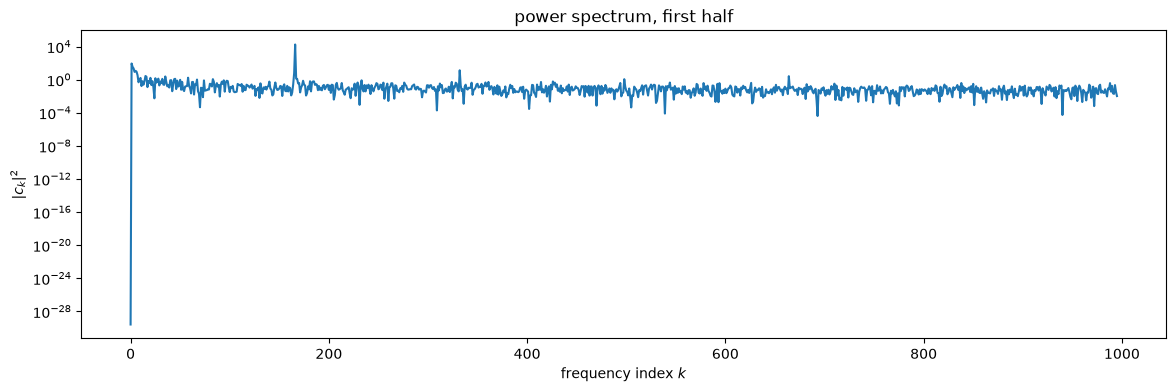

In [6]:
x = y - y.mean()

# SELFNOTE: The plot shows the power spectrum of the mean-centred temperature signal
# ck is the Fourier coefficient for frequency k. It tells us how much of the Fourier basis
# vector fk appears in the signal
# powerk = ck^2 (squared magnitude)

# ========= YOUR CODE STARTS HERE ========= #
c = dft(x)                  # coordinates of x in the Fourier basis
power = np.abs(c) ** 2      # |c_k|^2, the energy carried by coordinate k
# ========== YOUR CODE ENDS HERE ========== #

plt.figure(figsize=(14, 4))
plt.semilogy(power[:N // 2])
plt.xlabel("frequency index $k$"); plt.ylabel("$|c_k|^2$")
plt.title("power spectrum, first half"); plt.show()

### **2.1** Find the peak and interpret it

1. Report the index $k^{\star}$ of the largest $|c_k|^2$ for $1 \le k < N/2$.
2. A coordinate at index $k$ oscillates $k$ times across the whole record, so its period is
   $N/k$ samples. Convert $k^{\star}$ to a period in months. Is it what you expected?
3. Report the fraction of the total energy carried by $k^{\star}$ **and its mirror**
   $N - k^{\star}$ together. (Why must you count both? Your signal is real; what does that
   force on $\mathbf{c}$?)

   *Hint: this is not in the notes, so derive it. Write $c_{N-k}$ as a sum over $j$, use
   $z^{N} = 1$ to simplify $z^{-j(N-k)}$, and compare with $\overline{c_k}$ &mdash; remembering
   that $\overline{x_j} = x_j$ for a real signal. Two lines. You will need the result in
   4.0.*
4. $N = 1992 = 12 \times 166$. Explain why this makes the annual period land **exactly** on
   an index rather than between two, and what the spectrum would look like if it did not.


In [7]:
# ========= YOUR CODE STARTS HERE ========= #
k_max = 1 + np.argmax(power[1:N // 2])
period_months = N / k_max
mirror_index = N - k_max
energy_fraction = (power[k_max] + power[mirror_index]) / power.sum()

print(f"largest nonzero frequency index: k* = {k_max}")
print(f"period: {period_months:.1f} months")
print(f"mirror index: {mirror_index}")
print(f"energy in the pair: {energy_fraction:.4%}")
print(f"c[N-k*] is conj(c[k*]): {np.allclose(c[mirror_index], np.conj(c[k_max]))}")
# ========== YOUR CODE ENDS HERE ========== #


largest nonzero frequency index: k* = 166
period: 12.0 months
mirror index: 1826
energy in the pair: 98.1172%
c[N-k*] is conj(c[k*]): True


---
1. 166

2. 12 month. This is the expected because it's 1 year cycle.

3. Together they carry $~98.12\%$, of the total energy. We count both cause the original data is real, so we need imaginary part gone (when we reconstruct singnal imaginary parts of the frequency $k$ and it's mirror $N - k$ cancel each other) 

4. Because $N=1992=12\times166$, we have the natural number of cycles (exactly 166 years), the annual frequency has the integer index $k=N/12=166$, so it matches a Fourier basis wave exactly. If it wasn't the case, the annual frequency would fall between two Fourier indices.
---

### **2.2** The bridge back to Core A

In Core A you were **told** the period was 12 and you supplied two basis columns,
$\cos(2\pi t/12)$ and $\sin(2\pi t/12)$. Here you were told nothing and the data produced
$k^{\star}$.

1. Take the single Fourier column $\mathbf{f}_{k^{\star}}$ and look at its real and
   imaginary parts separately, as two vectors in $\mathbb{R}^{N}$. Plot the first 36
   entries of each. Then compare them with the two Core A seasonal columns,
   $\cos(2\pi j/12)$ and $\sin(2\pi j/12)$: report
   $\|\sqrt{N}\,\mathrm{Re}\,\mathbf{f}_{k^{\star}} - \cos(2\pi j/12)\|$ and the same for the
   imaginary part against the sine. What do you get, and why is it that rather than merely
   something small?

   *Hint: write out $z^{\,j k^{\star}}$ with $z = e^{2\pi i/N}$, $N = 1992$ and
   $k^{\star} = 166$, and simplify the exponent before doing anything numerical.*
2. So the two approaches found the same thing. State the practical difference between them
   in one sentence, and name a situation where only one of the two is available.
3. Look at $k = 2k^{\star}$ and $k = 3k^{\star}$ in the spectrum. What are those, and what
   does their size tell you about the *shape* of the annual cycle?


In [8]:
# ========= YOUR CODE STARTS HERE ========= #

# ========== YOUR CODE ENDS HERE ========== #


---
\### **YOUR ANSWER HERE** \###

---


---
## 3. The cost, and the algorithm that removes it

Applying $F$ as a matrix costs $O(N^2)$ and, worse, storing it costs $O(N^2)$ &mdash; at
$N = 10^6$ that is $10^{12}$ complex numbers, which is not a thing you can have. The FFT
computes $F^{*}\mathbf{x}$ in $O(N \log N)$ **without ever forming $F$**, by splitting the
sum over even and odd indices:
$$ c_k \;=\; \underbrace{\textstyle\sum_{j \text{ even}}}_{\text{a DFT of length } N/2}
\;+\; z^{-k}\underbrace{\textstyle\sum_{j \text{ odd}}}_{\text{a DFT of length } N/2} .$$


### **3.1** Why not on this series?

Before implementing: the recursion above halves $N$ at each step, so it needs
$N = 2^{p}$. Our series has $N = 1992 = 2^3 \cdot 3 \cdot 83$.

Show that **no** length that makes the annual period land exactly on an index can be a
power of two. (One line: what must $N$ be divisible by, and what is $12$ made of?)

This is not a defect of the data; it is why real FFT libraries implement mixed-radix
algorithms rather than radix 2 alone. Sections 3.2-3.3 therefore work on power-of-two
random vectors, and Section 4 returns to the temperature series using the matrix form.

---
$N$ must be divisible by $12=2^2\cdot3$

---

In [9]:
def fft_recursive(x: np.ndarray) -> np.ndarray:
    """Radix-2 Cooley-Tukey, returning the same thing as dft(x).

    Requires len(x) to be a power of two. Base case: length 1.

    Careful with the normalisation. Our dft() divides by sqrt(N) once, at
    the top level; a recursive call on length N/2 would divide by
    sqrt(N/2). Decide where the factor goes and be consistent -- the test
    below will catch you if you are not.
    """
    n = x.shape[0]
    assert n & (n - 1) == 0, "length must be a power of two"
    # ========= YOUR CODE STARTS HERE ========= #
    if n == 1:
        return x.astype(complex, copy=True)

    even = fft_recursive(x[::2])
    odd = fft_recursive(x[1::2])
    twiddle = np.exp(-2j * np.pi * np.arange(n // 2) / n)

    first_half = even + twiddle * odd
    second_half = even - twiddle * odd
    return np.concatenate((first_half, second_half)) / np.sqrt(2)
    # ========== YOUR CODE ENDS HERE ========== #


def test_fft():
    rng = np.random.default_rng(2)
    for n in (1, 2, 8, 64):
        v = rng.standard_normal(n) + 1j * rng.standard_normal(n)
        assert np.allclose(fft_recursive(v), dft(v), atol=1e-10), f"mismatch at n={n}"
    print("TEST 3: SUCCESS -- recursion agrees with the matrix form")

test_fft()


TEST 3: SUCCESS -- recursion agrees with the matrix form


### **3.2** Measure the two costs

Time your matrix `dft` and your `fft_recursive` on random vectors of length
$2^{p}$ for $p = 4, \dots, 12$, and plot both on log-log axes. Add `np.fft.fft` as a third
line.

1. Fit a straight line to each log-log curve and report the slopes. What slope does theory
   predict for each of the three?
2. At which $N$ does your recursion overtake your matrix version? Is it where you expected,
   and if not, what is the recursion paying that the flop count does not show?
3. `np.fft.fft` is also $O(N\log N)$, and it will still beat your recursion by a wide
   margin. Name two reasons that have nothing to do with the asymptotics.


matrix DFT slope: 1.972
recursive FFT slope: 1.000
NumPy FFT slope: 0.386
first measured recursive crossover: N = 128


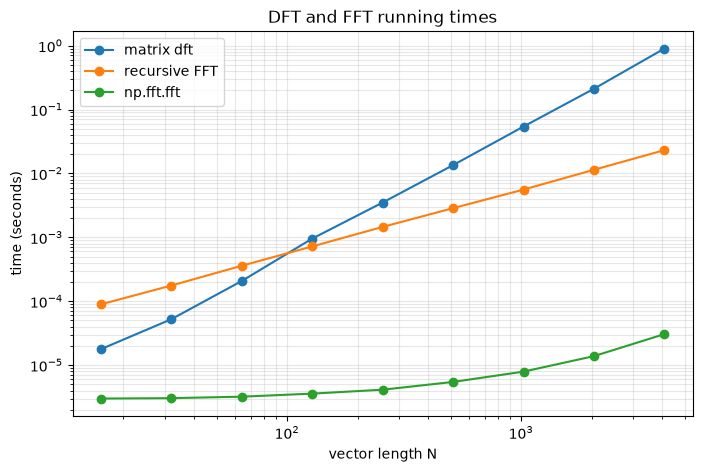

In [18]:
# ========= YOUR CODE STARTS HERE ========= #
def benchmark(function, vector, repeats):
    times = []
    for _ in range(repeats):
        start = perf_counter()
        function(vector)
        times.append(perf_counter() - start)
    return min(times)


rng = np.random.default_rng(3)
sizes = 2 ** np.arange(4, 13)
matrix_times = []
recursive_times = []
numpy_times = []

for n in sizes:
    vector = rng.standard_normal(n) + 1j * rng.standard_normal(n)
    matrix_times.append(benchmark(dft, vector, repeats=3))
    recursive_times.append(benchmark(fft_recursive, vector, repeats=3))
    numpy_times.append(benchmark(np.fft.fft, vector, repeats=20))

matrix_times = np.array(matrix_times)
recursive_times = np.array(recursive_times)
numpy_times = np.array(numpy_times)

matrix_slope = np.polyfit(np.log(sizes), np.log(matrix_times), 1)[0]
recursive_slope = np.polyfit(np.log(sizes), np.log(recursive_times), 1)[0]
numpy_slope = np.polyfit(np.log(sizes), np.log(numpy_times), 1)[0]

faster = np.flatnonzero(recursive_times < matrix_times)
crossover = sizes[faster[0]] if faster.size else None

print(f"matrix DFT slope: {matrix_slope:.3f}")
print(f"recursive FFT slope: {recursive_slope:.3f}")
print(f"NumPy FFT slope: {numpy_slope:.3f}")
print(f"first measured recursive crossover: N = {crossover}")

plt.figure(figsize=(8, 5))
plt.loglog(sizes, matrix_times, "o-", label="matrix dft")
plt.loglog(sizes, recursive_times, "o-", label="recursive FFT")
plt.loglog(sizes, numpy_times, "o-", label="np.fft.fft")
plt.xlabel("vector length N")
plt.ylabel("time (seconds)")
plt.title("DFT and FFT running times")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()
# ========== YOUR CODE ENDS HERE ========== #


---
1. On this run, the fitted slopes were approximately $~2$ for the matrix DFT, $~1$ for the recursive FFT, and $~0.39$ for `np.fft.fft`. TODO: What theory predicts.

2. The recursive FFT overtook the matrix DFT at $N=128$. Before that, the benefit was hidden behind the work big O notation doesn't take into account (like function calls and everything else needed to perform them)

3. NumPy most probably useses C underneeth for heavy lifting and is heavily optimized. In our fft implementation we just doing everything in Python without a smallest thought of making it run faster. 

---


### **3.3** Matrix-free, and why it matters beyond speed

Your `dft` builds an $N \times N$ matrix; `fft_recursive` builds nothing. For
$N = 2^{20}$, state the memory each would need, in bytes, for complex128.

Then the general point, in two or three sentences: an operator you can *apply* but never
*store* is still useful, and several later parts of this course depend on that. Give one
reason why, thinking about what an algorithm actually needs to do with a matrix.

---
A complex128 number needs 16 bytes. For $N=2^{20}$:
- DFT $16N^2$ 16 TB
- FFT $16N$ 16 MB

If we can compute something without storing input data, then it's useful.

---


---
## 4. Keeping the large coordinates

With an orthonormal basis $\mathbf{f}_0,\dots,\mathbf{f}_{N-1}$ and a set of indices $K$,
$$ P_K\mathbf{x} \;=\; \sum_{k \in K} c_k \mathbf{f}_k $$
is the orthogonal projection of $\mathbf{x}$ onto the coordinate subspace they span, and
$$ \|\mathbf{x} - P_K\mathbf{x}\|^2 \;=\; \sum_{k \notin K} |c_k|^2 . $$
The error is exactly the energy you discarded. Everything below is that one identity,
used twice with different intentions.


In [19]:
def keep_largest(c: np.ndarray, m: int) -> np.ndarray:
    """Zero all but the m coordinates of largest modulus."""
    # ========= YOUR CODE STARTS HERE ========= #
    out = np.zeros_like(c)
    largest_indices = np.argsort(np.abs(c))[-m:]
    out[largest_indices] = c[largest_indices]
    # ========== YOUR CODE ENDS HERE ========== #
    return out


### **4.0** An experiment before you use it

Reconstruct with `m = 2`, then with `m = 3`, and in each case report
`np.abs(reconstruction.imag).max()`.

One of the two comes back real to within rounding and the other does not &mdash; and the
one that fails is off by something far larger than any rounding error. Explain it, using
your answer to 2.1(3). Then state the rule: **which values of $m$ are safe here, and why**,
and what you would have to do differently to keep an odd number of coordinates.

*(This is not a detour. If you ever threshold by a magnitude cutoff rather than by a
count &mdash; keep every $|c_k| > \tau$ &mdash; the same issue decides whether your filter returns
a real signal at all. Everything below uses even $m$ for exactly this reason.)*


In [21]:
# ========= YOUR CODE STARTS HERE ========= #
reconstructions = {}

for m in (2, 3):
    kept_coordinates = keep_largest(c, m)
    reconstruction = idft(kept_coordinates)
    reconstructions[m] = reconstruction
    max_imaginary = np.abs(reconstruction.imag).max()
    print(f"m = {m}: max imaginary part = {max_imaginary:.6e}")
# ========== YOUR CODE ENDS HERE ========== #


m = 2: max imaginary part = 1.943337e-10
m = 3: max imaginary part = 2.121541e-01


---
For $m=2$, the maximum imaginary part is $~1.94\times10^{-10}$, which is numerical rounding. For $m=3$, it is $~2.12\times10^{-1}$, which is clearnly not a rounding error.

The two largest coordinates are the conjugate pair $k=166$ and $N-k=1826$. Keeping both preserves the symmetry $c_{N-k}=\overline{c_k}$, so their imaginary parts cancel during reconstruction. With $m=3$, one member of the next pair is kept without its mirror, breaking conjugate symmetry and producing a genuinely complex reconstruction.

Therefore, even values of $m$ are safe here because the nonzero-frequency coefficients of a real signal occur in conjugate pairs. To keep an odd number while retaining a real reconstruction, the unpaired coordinate must be a self-conjugate one: $k=0$, or $k=N/2$ when $N$ is even; otherwise, include the missing mirror and keep an even number instead.

---


### **4.1** Verify the identity, then use it

1. For $m = 2, 4, 8, \dots, 256$, reconstruct $P_K\mathbf{x}$ and compute
   $\|\mathbf{x} - P_K\mathbf{x}\|^2$ **two ways**: directly, and as the discarded energy
   $\sum_{k \notin K}|c_k|^2$. Confirm they agree.
2. Plot the fraction of energy retained against $m$. How many coordinates out of
   $N = 1992$ are needed for 98% of the energy?
3. Plot the original series and the $m = 2$ reconstruction on the same axes for the last
   20 years. What has been kept and what has been lost?


In [13]:
# ========= YOUR CODE STARTS HERE ========= #

# ========== YOUR CODE ENDS HERE ========== #


---
\### **YOUR ANSWER HERE** \###

---


### **4.2** Compressible in this basis, or compressible?

Your energy curve is close to flat after a handful of coordinates. Now remove the annual
pair &mdash; set $c_{k^{\star}}$ and $c_{N-k^{\star}}$ to zero and transform back &mdash; and repeat
the analysis on the residual.

1. How many coordinates does the *residual* need for 98% of its energy? Compare with your
   answer for the full series.
2. So: is this signal compressible, or is one component of it compressible? Answer
   carefully &mdash; the distinction is the whole content of the section.
3. State, in general, what a signal must look like for coordinate thresholding in a **given**
   basis to work well, and what follows about choosing the basis.


In [14]:
# ========= YOUR CODE STARTS HERE ========= #

# ========== YOUR CODE ENDS HERE ========== #


---
\### **YOUR ANSWER HERE** \###

---


### **4.3** The same operation, called denoising

Corrupt the series with noise: `y_noisy = y + sigma * rng.standard_normal(N)` with
`sigma = 2.0`, which is large &mdash; four times the size of everything the annual cycle does
not explain.

1. Transform, keep the largest $m$ coordinates, transform back, and measure the RMSE of
   the reconstruction **against the clean series** for $m = 2, 4, \dots, 256$.
2. Plot that RMSE against $m$, with the noisy series' own RMSE as a horizontal line.
   The curve is not monotone. Find the $m$ that minimises it.
3. Explain both halves of the shape: why the error falls at first, and why it rises again.
   What is being added back as $m$ grows?
4. Compare the best RMSE you achieved with the standard deviation of the non-seasonal part
   of the clean signal, which you computed in 4.2. Why can no choice of $m$ do much better
   than that number?
5. You have used exactly the operation from 4.1, with the same code. What changed?


In [15]:
rng = np.random.default_rng(0)
sigma = 2.0
y_noisy = y + sigma * rng.standard_normal(N)

# Subtract the mean before transforming, and add it back after, exactly as
# you did in section 2. If you leave it in, coordinate k=0 is the largest
# of all and spends one of your m slots re-learning the average -- which
# makes the m=2 reconstruction look far worse than it is.

# ========= YOUR CODE STARTS HERE ========= #

# ========== YOUR CODE ENDS HERE ========== #


---
\### **YOUR ANSWER HERE** \###

---


---
## 5. Summary

A few sentences each. These are where the defence starts.

1. The DFT is a change of basis. Name three concrete things in this notebook that would
   have failed, or needed extra work, if that basis had been merely a basis rather than an
   **orthonormal** one.
2. Core A found the annual cycle by being told to look for it; Core B found it by looking.
   Which would you use on a signal whose structure you did not already know, and what is
   the cost of that choice?
3. Compression and denoising were the same three lines of code. State the one sentence
   that explains why, and what distinguishes the two in practice.
4. You built $F$ explicitly and then were told never to do that again. When *is* the
   explicit matrix the right thing to have?

---
\### **YOUR ANSWER HERE** \###

---


---
---
# $\star$ Extension (bonus)

> **Optional. Up to 1 bonus point for the whole lab.** Attempt **at most one** of the three
> extensions &mdash; Extension 3 is below, Extensions 1 and 2 are at the end of Core A. The
> point is for a **finding you can defend**, not for code that ran. Say in your `README`
> which one you chose.

Everything above this line is Core B and is marked in full without this.


---
## $\star$ Extension 3 (bonus): DCT against DFT

The discrete cosine transform uses the orthonormal basis
$$ C_{kn} = \alpha_k \cos\!\Big(\frac{\pi (2n+1) k}{2N}\Big), \qquad
\alpha_0 = \sqrt{1/N},\ \alpha_k = \sqrt{2/N}\ (k \ge 1), $$
and it is the transform inside `jpeg` and most audio codecs. The usual claim is that its
coefficients decay faster than the DFT's. Test that claim on this series &mdash; and be
prepared for it to be only half true.

1. Build $C$ as a matrix, check that it is orthogonal, and check it against
   `scipy.fft.dct(x, norm='ortho')` if you have scipy.
2. For the mean-subtracted series, plot the sorted energies $|c_k|^2$ in both bases on one
   log-scale plot, and report how many coefficients each needs for 98% and for 99.5% of
   the energy. **Which basis wins?**
3. Now repeat on the **residual** from Core B 4.2 &mdash; the series with the annual pair
   removed. **Which basis wins now?**
4. The finding: explain both results. For the first, think about what $N = 12 \times 166$
   did for the DFT, and whether the DCT's cosines can represent a sinusoid of arbitrary
   phase. For the second, plot the residual and look at its two ends: what does the DFT
   assume happens after the last sample, and what does the DCT assume?
5. So: when is the DCT the better basis, and why is that the usual case for images?


In [16]:
# ========= YOUR CODE STARTS HERE ========= #

# ========== YOUR CODE ENDS HERE ========== #


---
\### **YOUR FINDING HERE** \###

---
